# 04 · Do Launches and Rules Cause Booms? Event Studies (Phase P4)

Research question **RQ3**. P3 found no robust *correlation* between slow-moving country conditions and growth. P4 uses
**sharp, dated events** instead: each country is compared with itself before and after a launch, against countries
that had not launched yet. That is the design best suited to so few countries.

| # | Hypothesis | Event (from `drivers/events.csv`, verified only) | Outcome |
|---|---|---|---|
| **H3** | National QR / real-time payment rails **cause** digital-payment growth | first national rail per country | IMF FAS mobile money and mobile banking, % GDP |
| **H4a** | Digital-bank licensing causes growth | digital-bank framework / licence | IMF FAS mobile & internet banking, % GDP |
| **H4b** | Ride-hailing legalisation causes growth | legalisation in force | e-Conomy transport & food, % GDP |
| **H9** | Crypto ecosystem-building follows **regulatory clarity** | crypto licensing regime in force | Orbis new crypto firms per million |
| **H5** | Anchor platforms speed takeoff | super-app wallet launch (`drivers/anchors.csv`) | dated fintech takeoffs (descriptive) |

**Method (frozen, PREREGISTRATION.md §5):** Callaway & Sant'Anna (2021) group-time effects with **not-yet-treated**
controls, aggregated by event time. Supported if the post-event effect is positive and significant **and** the
pre-trend test is not rejected (p > 0.10).

**Inference for few countries:** **exact randomization inference**. Every way of reassigning the observed launch years
across the countries is tried, and the p-value is the share of reassignments with an effect at least as large as the
real one. This is valid for any number of units, where asymptotic standard errors are not.

**Treatment timing rule (fixed here before any estimate):** an event that takes effect in **January–June** treats that
calendar year; **July–December** treats the next year (annual data).

In [1]:
import sys, itertools, warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from drivers.config import PROC, FIG, ROOT, NAME
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)

EV = pd.read_csv(ROOT / "drivers" / "events.csv", parse_dates=["date"])
EV = EV[EV.status.str.startswith("verified")]
EV["onset"] = np.where(EV.date.dt.month <= 6, EV.date.dt.year, EV.date.dt.year + 1)
print(f"{len(EV)} verified events used")

def first_onset(category, direction="+"):
    e = EV[(EV.category == category) & (EV.direction == direction)]
    return e.sort_values("date").groupby("iso3").onset.first().to_dict()

36 verified events used


## 1 · Estimator: Callaway–Sant'Anna ATT(g, t) with not-yet-treated controls
* **Post periods (t ≥ g):** ATT(g, t) = mean change Y[t] − Y[g−1] in cohort g minus the same change among units not yet
  treated at t.
* **Pre periods (t < g):** "varying base" one-year changes Y[t] − Y[t−1], cohort vs not-yet-treated. These should be about 0.
* Aggregated by event time e = t − g, weighting cohorts by size. **Overall effect** = mean of e = 0…3.

In [2]:
def att_gt(Y, cohorts, t, g, e_pre):
    """Y: wide frame (units x years). cohorts: {unit: onset year or inf}."""
    treated = [u for u, c in cohorts.items() if c == g]
    ctrl = [u for u, c in cohorts.items() if c > max(t, g - 1) and u in Y.index]
    if not treated or not ctrl: return np.nan
    if e_pre:
        a, b = t - 1, t
    else:
        a, b = g - 1, t
    if a not in Y.columns or b not in Y.columns: return np.nan
    dT = (Y.loc[treated, b] - Y.loc[treated, a]).dropna(); dC = (Y.loc[ctrl, b] - Y.loc[ctrl, a]).dropna()
    if len(dT) == 0 or len(dC) == 0: return np.nan
    return dT.mean() - dC.mean()

def event_study(Y, cohorts, window=(-4, 3)):
    rows = []
    for g in sorted({c for c in cohorts.values() if np.isfinite(c)}):
        size = sum(1 for c in cohorts.values() if c == g)
        for e in range(window[0], window[1] + 1):
            if e == -1: continue
            t = g + e
            v = att_gt(Y, cohorts, t, g, e_pre=(e < 0))
            if v == v: rows.append(dict(g=g, e=e, att=v, w=size))
    R = pd.DataFrame(rows)
    if R.empty: return R, np.nan, np.nan
    es = R.groupby("e").apply(lambda d: np.average(d.att, weights=d.w)).rename("att").reset_index()
    post = es[es.e.between(0, 3)].att.mean()
    pre = es[es.e <= -2].att.mean() if (es.e <= -2).any() else np.nan
    return es, post, pre

def randomization_test(Y, cohorts, max_perms=50000, seed=1):
    """Exact (or Monte Carlo if huge) RI over reassignments of the onset years across units."""
    units = [u for u in cohorts if u in Y.index]
    onsets = [cohorts[u] for u in units]
    es, post, pre = event_study(Y, {u: cohorts[u] for u in units})
    perms = set(itertools.permutations(onsets)) if math.factorial(len(units)) <= max_perms else None
    rng = np.random.default_rng(seed)
    draws = list(perms) if perms else [tuple(rng.permutation(onsets)) for _ in range(max_perms)]
    post_null, pre_null = [], []
    for p in draws:
        _, a, b = event_study(Y, dict(zip(units, p)))
        if a == a: post_null.append(a)
        if b == b: pre_null.append(b)
    post_null, pre_null = np.array(post_null), np.array(pre_null)
    return dict(es=es, post_att=post, pre_att=pre, n_units=len(units), n_reassignments=len(draws),
                p_post_two_sided=float(np.mean(np.abs(post_null) >= abs(post) - 1e-12)) if len(post_null) else np.nan,
                p_post_one_sided=float(np.mean(post_null >= post - 1e-12)) if len(post_null) else np.nan,
                p_pretrend=float(np.mean(np.abs(pre_null) >= abs(pre) - 1e-12)) if (len(pre_null) and pre == pre) else np.nan)

def wide(df, value="y"):
    return df.pivot_table(index="iso3", columns="year", values=value)

def cohorts_for(Yw, onsets):
    """Onset counts only if it falls inside that unit's own observed years (else never-treated in the window)."""
    out = {}
    for u in Yw.index:
        yrs = Yw.loc[u].dropna().index
        c = onsets.get(u, np.inf)
        out[u] = c if (np.isfinite(c) and yrs.min() < c <= yrs.max()) else np.inf
    return out

def plot_es(res, title, ax):
    es = res["es"]
    if es is None or len(es) == 0: ax.set_title(title + " (not estimable)"); return
    ax.axhline(0, color="#999", lw=1); ax.axvline(-0.5, color="#999", ls=":", lw=1)
    ax.plot(es.e, es.att, "-o", color="#2a78d6")
    ax.scatter([-1], [0], color="#2a78d6", facecolor="white", zorder=3)
    ax.set_title(f"{title}\npost ATT {res['post_att']:+.2f}, RI p = {res['p_post_two_sided']:.2f}; pre-trend p = {res['p_pretrend']:.2f}", fontsize=9)
    ax.set_xlabel("years since event (−1 = reference)")

## 2 · H3: national QR / real-time payment rails → digital payments
Cohort = the country's **first** verified national rail (QR standard or real-time transfer). Outcome = asinh(% of GDP),
so effects read roughly as log points. Countries without a rail inside the data window act as never-treated controls.

In [3]:
P = pd.read_parquet(PROC / "outcome_panel.parquet"); P = P[~P.is_estimate]
rail = first_onset("payment_rail")
print("rail onsets:", {NAME[k]: v for k, v in rail.items()})
res, fig_items = {}, []
for s in ["fas_mobile_money", "fas_mobile_banking"]:
    d = P[P.series == s].assign(y=lambda x: np.arcsinh(x.value))
    Yw = wide(d)
    coh = cohorts_for(Yw, rail)
    res[("H3", s)] = randomization_test(Yw, coh)
    res[("H3", s)]["cohorts"] = {NAME[u]: (int(c) if np.isfinite(c) else "never") for u, c in coh.items()}
    fig_items.append((("H3", s), f"H3 rails → {s.replace('fas_', '')}"))
pd.DataFrame({k: {m: v[m] for m in ["n_units", "n_reassignments", "post_att", "p_post_two_sided", "p_pre_trend" if False else "p_pretrend", "cohorts"]} for k, v in res.items() if k[0] == "H3"}).T

rail onsets: {'Indonesia': 2020, 'Cambodia': 2021, 'Myanmar': 2025, 'Malaysia': 2019, 'Philippines': 2018, 'Singapore': 2018, 'Thailand': 2017, 'Vietnam': 2021}


n_units n_reassignments  post_att p_post_two_sided p_pretrend                                            cohorts
H3 fas_mobile_money         8            1680  0.192599         0.602748   0.623508  {'Indonesia': 2020, 'Cambodia': 2021, 'Myanmar...
   fas_mobile_banking       7             840  -0.21558         0.402381   0.379475  {'Indonesia': 2020, 'Cambodia': 'never', 'Myan...

## 3 · H4: licences and legalisation
**H4a** digital-bank frameworks/licences → mobile & internet banking. **H4b** ride-hailing legalisation →
e-Conomy transport & food. For H4b, the Philippines (2015) and Indonesia (2017) were treated **before** the data
starts (2019) and cannot be used. That leaves Malaysia, Vietnam and Thailand with almost no not-yet-treated controls,
so H4b is reported only if it is estimable. **The e-scooter ban (Singapore 2019) has no outcome series**, so it is not testable.

In [4]:
bank = first_onset("digital_bank")
d = P[P.series == "fas_mobile_banking"].assign(y=lambda x: np.arcsinh(x.value)); Yw = wide(d)
coh = cohorts_for(Yw, bank)
res[("H4a", "digital_bank")] = randomization_test(Yw, coh)
res[("H4a", "digital_bank")]["cohorts"] = {NAME[u]: (int(c) if np.isfinite(c) else "never") for u, c in coh.items()}
fig_items.append((("H4a", "digital_bank"), "H4a digital-bank licences → mobile banking"))

ride = first_onset("ride_hailing_rule")
d = P[P.series == "econsea_transport_food"].assign(y=lambda x: np.log(x.value)); Yw = wide(d)
coh = {u: ride.get(u, np.inf) for u in Yw.index}
coh = {u: c for u, c in coh.items() if not (np.isfinite(c) and c <= Yw.columns.min())}       # drop already-treated
coh = {u: c for u, c in cohorts_for(Yw.loc[list(coh)], coh).items()}
res[("H4b", "ride_hailing")] = randomization_test(Yw, coh)
res[("H4b", "ride_hailing")]["cohorts"] = {NAME[u]: (int(c) if np.isfinite(c) else "never") for u, c in coh.items()}
fig_items.append((("H4b", "ride_hailing"), "H4b ride-hailing legalisation → transport & food"))
pd.DataFrame({k: {m: v[m] for m in ["n_units", "n_reassignments", "post_att", "p_post_two_sided", "p_pretrend", "cohorts"]} for k, v in res.items() if k[0].startswith("H4")}).T

,,n_units,n_reassignments,post_att,p_post_two_sided,p_pretrend,cohorts
H4a,digital_bank,7,420,-0.152648,0.509524,0.135714,"{'Indonesia': 2022, 'Cambodia': 'never', 'Myan..."
H4b,ride_hailing,4,12,0.261771,0.5,NaN,"{'Malaysia': 2020, 'Singapore': 'never', 'Thai..."


## 4 · H9: crypto regulatory clarity → crypto firm formation
Outcome = asinh(new crypto firms per million), Orbis, **active firms only** (survivorship caveat), 2006–2024 (2025
incomplete). Countries with ≥ 20 crypto firms. Vietnam's regime starts in 2025, so it is never-treated in the window.
The pre-registered control for trading-volume share is **not possible**: Chainalysis ranks exist only from 2022 and
change method yearly (logged).

**Confound to keep in mind:** most regimes (2018–2020) arrived right at the global token-sale boom of 2017–18. The
not-yet-treated comparison removes shocks common to all countries, but only if the cycle hit every country alike.

In [5]:
ff = pd.read_parquet(ROOT / "data" / "licensed" / "derived" / "orbis_firm_formation_PRELIMINARY.parquet")
cr = ff[(ff.kind == "crypto") & ff.year.between(2006, 2024)]
keep = cr.groupby("iso3").new_firms.sum().loc[lambda s: s >= 20].index
cr = cr[cr.iso3.isin(keep)].assign(y=lambda x: np.arcsinh(x.new_per_million))
Yw = wide(cr)
crypto = first_onset("crypto_regime")
coh = cohorts_for(Yw, crypto)
res[("H9", "crypto_regime")] = randomization_test(Yw, coh)
res[("H9", "crypto_regime")]["cohorts"] = {NAME[u]: (int(c) if np.isfinite(c) else "never") for u, c in coh.items()}
fig_items.append((("H9", "crypto_regime"), "H9 crypto licensing regime → new crypto firms"))
pd.Series({m: res[("H9", "crypto_regime")][m] for m in ["n_units", "n_reassignments", "post_att", "p_post_two_sided", "p_pretrend", "cohorts"]})

n_units                                                             5
n_reassignments                                                    60
post_att                                                    -0.076209
p_post_two_sided                                             0.683333
p_pretrend                                                   0.866667
cohorts             {'Indonesia': 2019, 'Malaysia': 2019, 'Singapo...
dtype: object

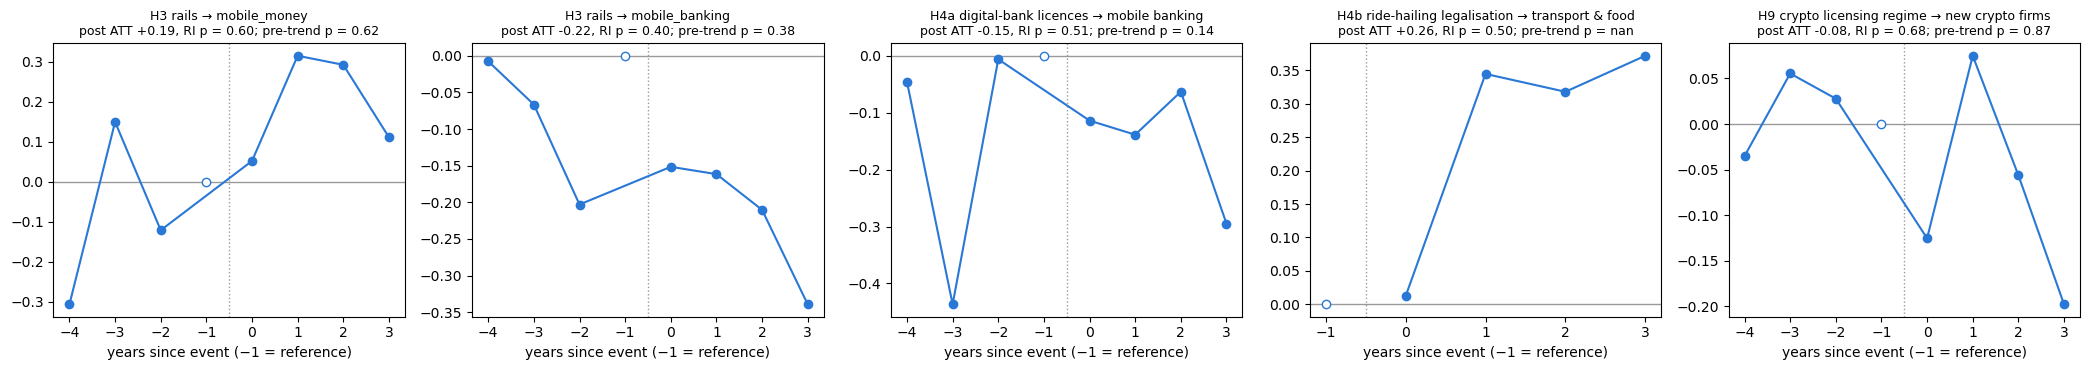

In [6]:
fig, axes = plt.subplots(1, len(fig_items), figsize=(4.2 * len(fig_items), 3.8), sharey=False)
for ax, (k, title) in zip(np.atleast_1d(axes), fig_items):
    plot_es(res[k], title, ax)
plt.tight_layout(); plt.savefig(FIG / "04_event_studies.png", dpi=150); plt.show()

## 5 · H5: anchor platforms (descriptive)
The anchor table (`drivers/anchors.csv`, two sources per date) records when a platform with a large existing user
base launched its own wallet. With 3–4 dated fintech takeoffs, a hazard model is not meaningful, so this is
**descriptive**: did takeoff come after the anchor launch?

In [7]:
anch = pd.read_csv(ROOT / "drivers" / "anchors.csv")
cat = pd.read_parquet(PROC / "boom_catalogue.parquet")
cat["takeoff_year"] = pd.to_numeric(cat.takeoff_year, errors="coerce")
fin = cat[cat.series.isin(["fas_mobile_money", "fas_mobile_banking", "rail_mys_emoney", "rail_duitnow_rpp"])]
h5 = fin.merge(anch[["iso3", "anchor_wallet", "launch_year"]], on="iso3", how="left")
h5["takeoff_minus_anchor"] = h5.takeoff_year - h5.launch_year
h5[["series", "country", "status", "takeoff_year", "anchor_wallet", "launch_year", "takeoff_minus_anchor"]].sort_values("takeoff_year")

,series,country,status,takeoff_year,anchor_wallet,launch_year,takeoff_minus_anchor
6,fas_mobile_money,Cambodia,boom,2011.0,NaN,NaN,NaN
1,fas_mobile_banking,Indonesia,boom,2016.0,GoPay,2016.0,0.0
0,fas_mobile_money,Indonesia,boom,2017.0,GoPay,2016.0,1.0
3,rail_mys_emoney,Malaysia,boom,2021.0,Touch 'n Go eWallet,2017.0,4.0
2,fas_mobile_money,Thailand,no datable takeoff (growing through window),NaN,Rabbit LINE Pay,2016.0,NaN
4,fas_mobile_money,Myanmar,no datable takeoff (growing through window),NaN,NaN,NaN,NaN
5,fas_mobile_banking,Malaysia,no datable takeoff (flat through window),NaN,Touch 'n Go eWallet,2017.0,NaN
7,fas_mobile_money,Malaysia,no datable takeoff (growing through window),NaN,Touch 'n Go eWallet,2017.0,NaN
8,fas_mobile_banking,Thailand,no datable takeoff (growing through window),NaN,Rabbit LINE Pay,2016.0,NaN
9,rail_duitnow_rpp,Malaysia,no datable takeoff (growing through window),NaN,Touch 'n Go eWallet,2017.0,NaN


## 6 · Results summary
| Hypothesis | Post-event effect | Randomization p | Pre-trend p | Verdict |
|---|---|---|---|---|
| **H3** rails → mobile money | **+0.19** log points (≈ +21%) | 0.60 | 0.62 | **Not supported**: right sign, indistinguishable from reassigned dates |
| **H3** rails → mobile & internet banking | −0.22 | 0.40 | 0.38 | **Not supported** |
| **H4a** digital-bank licences → mobile banking | −0.15 | 0.51 | 0.14 | **Not supported** |
| **H4b** ride-hailing legalisation → transport & food | +0.26 | 0.50 (only 12 reassignments) | not estimable | **Not identifiable**: 2 countries treated before data, too few controls |
| **H4c** bans (Singapore e-scooters) | — | — | — | **Not testable**: no outcome series |
| **H9** crypto regimes → new crypto firms | −0.08 | 0.68 | 0.87 | **Not supported** |
| **H5** anchor platforms (descriptive) | Indonesia's mobile banking (2016) and mobile money (2017) took off in the GoPay launch year or the year after; Malaysia's e-money took off 4 years after Touch 'n Go eWallet; Cambodia (no anchor) took off first, in 2011 | — | — | **Mixed / anecdotal** (3–4 cases) |

**Reading the results:**
* **No launch or rule has a detectable causal effect** at this sample size. Exact randomization inference over every
  reassignment of launch years shows each estimated effect is within the range that random timing produces.
* **The one result pointing the right way is H3 for mobile money** (+21% after a national rail, rising in years 1–2,
  with no pre-trend). With 8 countries it could not be told apart from chance; it is the result to recheck with the
  monthly central-bank series (QRIS, DuitNow, PromptPay, InstaPay), which would give far more data points per country.
* **H9:** crypto firm formation does not rise after licensing regimes. The 2017–18 token-sale boom and the 2021–22
  wave dominate every country at once, whatever their rules. That is consistent with formation following the
  **global cycle**, not local regulation. The active-firms-only bias leaves this open, since failed firms are missing.
* **H5:** Indonesia is the textbook anchor case (GoPay), but Cambodia, the region's first mover, had no anchor at all.
  Anchors are neither necessary nor clearly sufficient on this evidence.

**Power, plainly:** 4–8 countries per test. Exact RI is valid at any sample size, but it can only flag effects that
are large relative to how much countries differ.

In [8]:
# Save event-study points and summaries for the dashboard
pts, summ = [], []
for (h, s), r in res.items():
    if r["es"] is not None and len(r["es"]):
        pts += [dict(test=f"{h} {s}", e=int(e), att=float(a)) for e, a in zip(r["es"].e, r["es"].att)]
    summ.append(dict(test=f"{h} {s}", post_att=r["post_att"], p_ri=r["p_post_two_sided"], p_pretrend=r["p_pretrend"],
                     n_units=r["n_units"], n_reassignments=r["n_reassignments"]))
pd.DataFrame(pts).to_parquet(PROC / "event_study_points.parquet")
pd.DataFrame(summ).to_parquet(PROC / "event_study_summary.parquet")